# Customer analytics report: UK online gift retailer, Dec 2009 to Dec 2011

**Business questions**

1. How is the business trending, and how seasonal is it?
2. Do customers come back after their first order?
3. Who are the most valuable customers, and who is about to be lost?
4. Which products drive revenue, and which are bought together?

All numbers come from the SQL views in [`sql/`](../sql), run with DuckDB directly on the 1.07M-line Parquet file. This notebook only queries and presents them.

In [1]:
import pandas as pd
from IPython.display import Image, display

from retail.analysis import connect, data_quality_report

pd.set_option('display.float_format', '{:,.2f}'.format)
con = connect()
sql = lambda q: con.execute(q).df()
FIG = '../reports/figures/'

## 0. Data quality

What each cleaning rule in `sql/01_staging.sql` removes:

In [2]:
data_quality_report(con)

,step,lines
0,raw lines,1067371
1,exact duplicates removed,34335
2,bad-debt adjustments (A invoices),6
3,"non-product codes (postage, fees, vouchers...)",5817
4,zero or negative price,5961
5,clean lines (sales + returns),1021252
6,of which returns (C invoices),17914
7,of which without customer id,227089


* About **22% of clean lines have no customer ID** (guest checkouts). They count towards revenue KPIs but cannot be used for customer-level analysis.
* Returns are **kept as negative lines** rather than dropped, so that orders which were cancelled (including a single 80,995-unit order cancelled minutes later) net out of customer revenue.

## 1. Business trend and seasonality

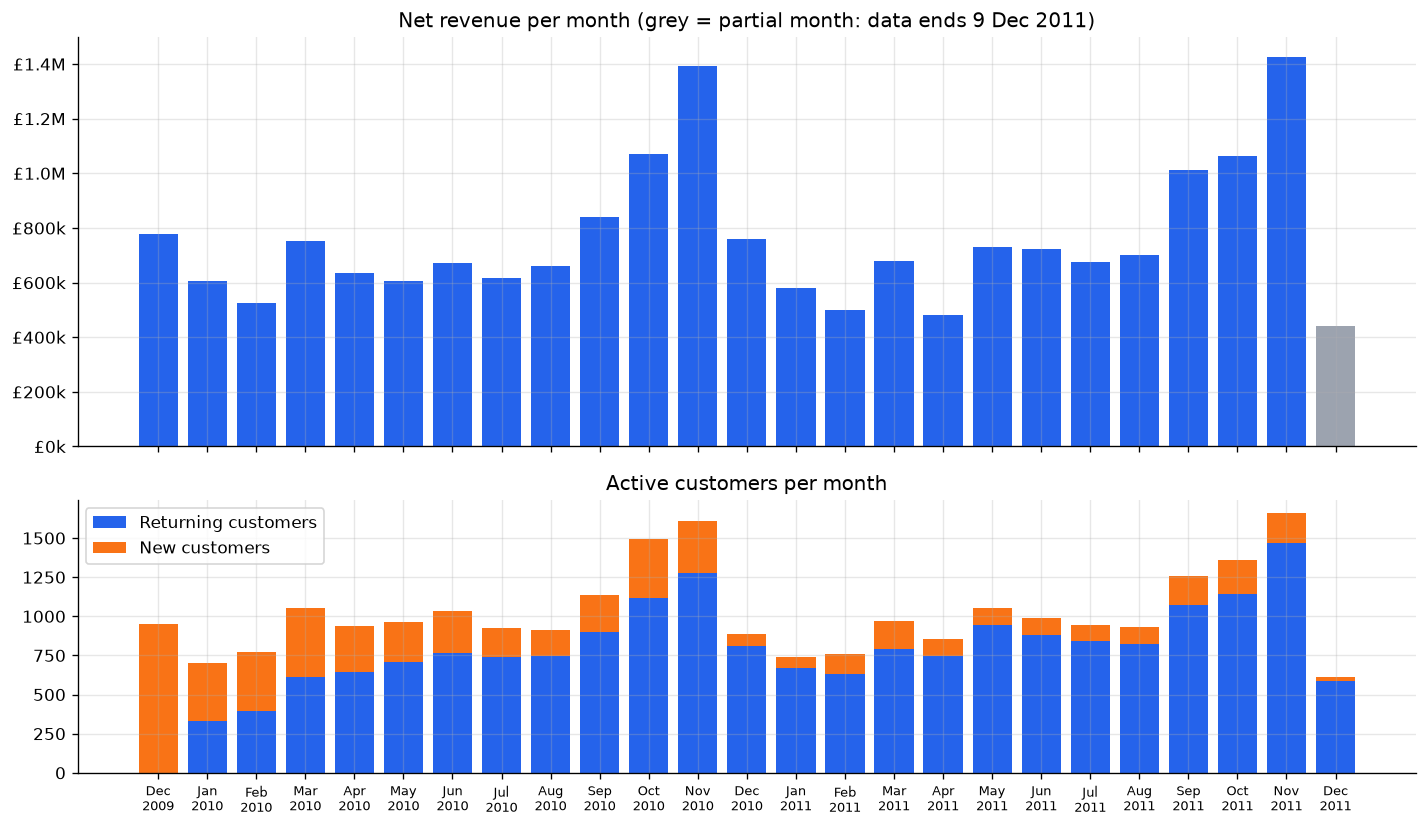

,year,net_revenue,orders,growth
0,2010,"8,377,759.66","18,077.00",NaN
1,2011,"8,572,828.10","17,407.00",0.02


In [3]:
kpis = sql('select * from monthly_kpis')
display(Image(FIG + 'monthly_kpis.png'))
yearly = sql('''
    select year(invoice_month) as year, sum(net_revenue) as net_revenue,
           sum(all_orders) as orders
    from monthly_kpis where invoice_month between '2010-01-01' and '2011-11-01'
      and month(invoice_month) <= 11
    group by 1 order by 1''')
yearly['growth'] = yearly['net_revenue'].pct_change()
yearly

* Strong **Q4 seasonality**: November is the peak month in both years, at roughly twice the revenue of a summer month, as customers stock up for Christmas.
* Comparing the same January–November window, revenue grew only **2%** year over year while the number of orders fell 4%: the business is essentially flat.
* The share of revenue from **returning customers** rises from ~70% to ~90% over the two years, while new customers per month fall sharply in 2011: the business lives off its existing base and acquisition is slowing.

In [4]:
sql('''select invoice_month, new_customers, returning_customers,
              round(returning_revenue_share, 3) as returning_revenue_share
       from monthly_kpis''').iloc[[1, 6, 12, 18, 23]]

,invoice_month,new_customers,returning_customers,returning_revenue_share
1,2010-01-01,368,333,0.70
6,2010-06-01,267,767,0.80
12,2010-12-01,76,808,0.95
18,2011-06-01,108,882,0.87
23,2011-11-01,191,1469,0.93


## 2. Retention: do customers come back?

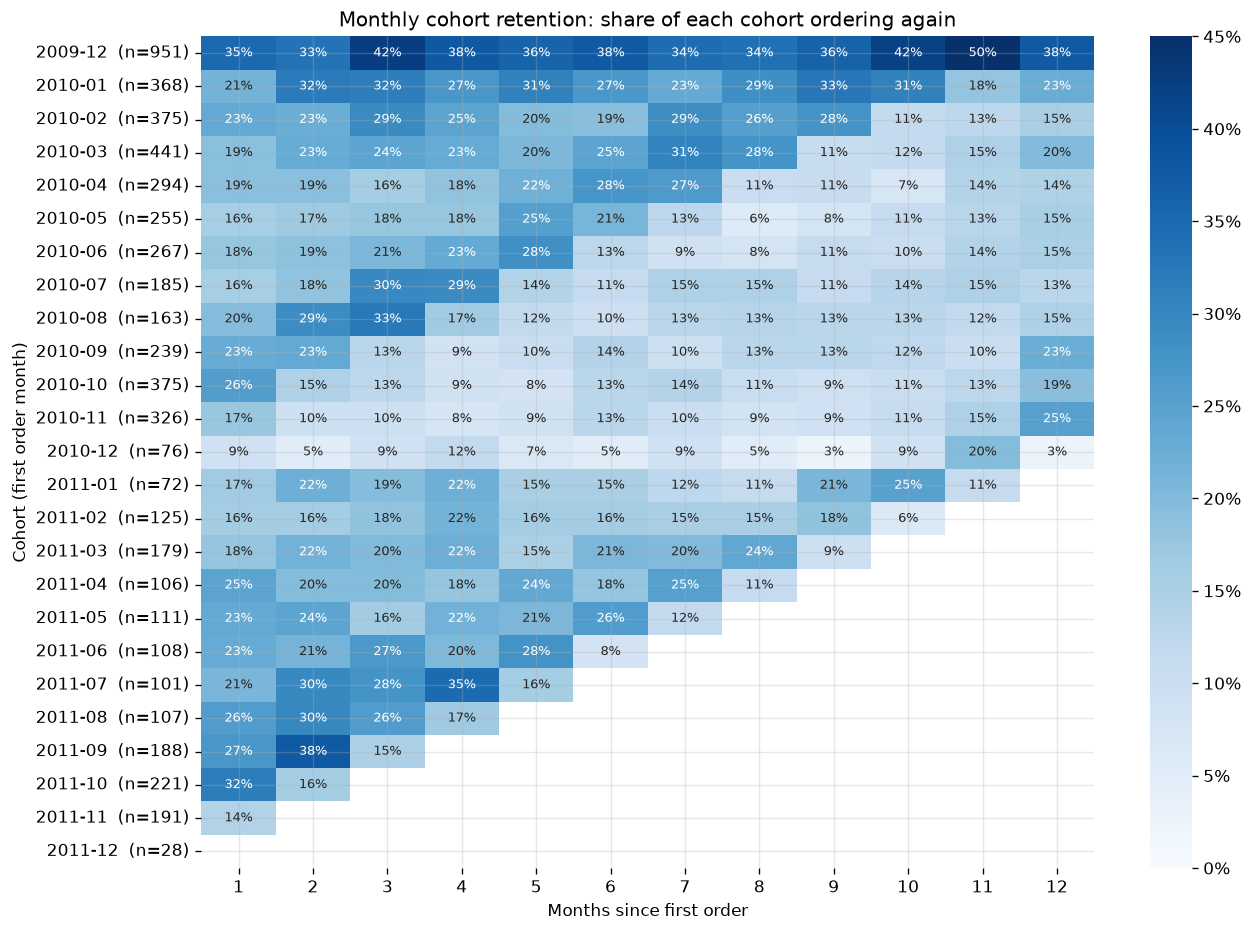

,months_since_first,retention_rate,cohorts
0,0,1.00,24
1,1,0.23,23
2,2,0.24,22
3,3,0.25,21
4,4,0.23,20
5,5,0.22,19
6,6,0.22,18
7,7,0.22,17
8,8,0.20,16
9,9,0.19,15


In [5]:
display(Image(FIG + 'cohort_retention.png'))
sql('select * from retention_curve')

* In any month after their first order, **about 1 customer in 4–5 orders again** (23% in month 1, still ~22% in month 12). There is no steep early drop-off: customers who stay keep buying, which is typical for a business with many wholesale buyers.
* The **December 2009 cohort looks much more loyal** (35–50%) because it is left-censored: it contains every customer who already existed when the data starts, not just new ones. It should be excluded when judging acquisition quality.
* Cohorts acquired in autumn 2010 show a **second peak 11–12 months later** (e.g. the November 2010 cohort: 25% active in November 2011): the Christmas season pulls lapsed customers back.

## 3. Customer value: RFM segmentation

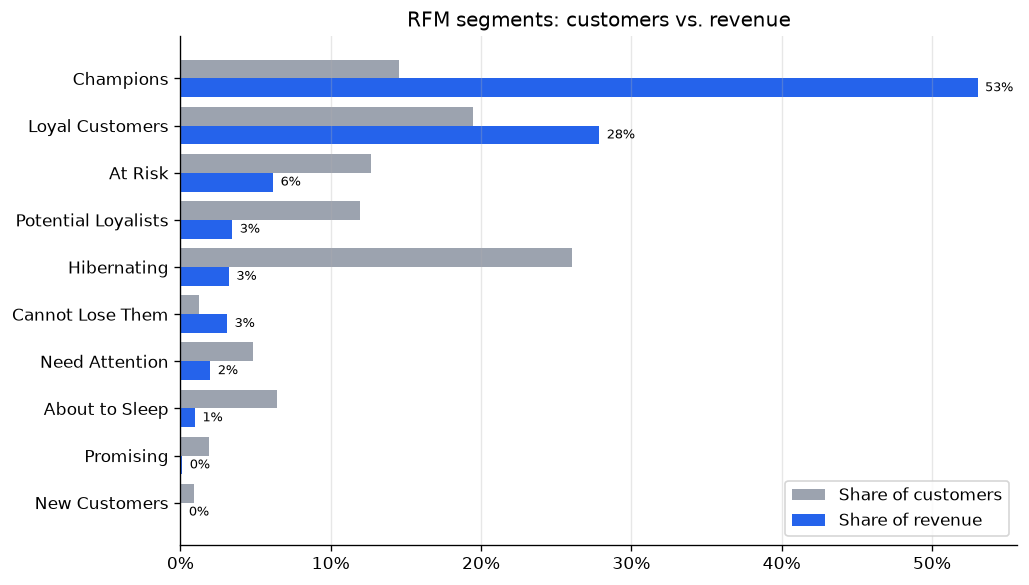

,segment,customers,customer_share,revenue,revenue_share,median_recency_days,median_orders,median_revenue
0,Champions,847,0.15,"8,676,162.02",0.53,9.00,11.00,"3,856.97"
1,Loyal Customers,1137,0.19,"4,559,566.70",0.28,54.00,8.00,"2,488.49"
2,At Risk,739,0.13,"1,009,428.09",0.06,374.00,4.00,"1,048.86"
3,Potential Loyalists,699,0.12,"564,546.54",0.03,25.00,3.00,663.52
4,Hibernating,1521,0.26,"527,975.78",0.03,433.00,1.00,261.70
5,Cannot Lose Them,74,0.01,"508,237.08",0.03,315.50,11.00,"3,858.58"
6,Need Attention,280,0.05,"325,745.22",0.02,98.00,3.00,896.26
7,About to Sleep,375,0.06,"158,796.54",0.01,97.00,1.00,329.34
8,Promising,111,0.02,"20,426.43",0.00,37.00,1.00,172.37
9,New Customers,52,0.01,"10,685.73",0.00,11.50,1.00,197.11


In [6]:
display(Image(FIG + 'rfm_segments.png'))
sql('select * from rfm_segment_summary')

* **Champions** (bought recently and often) are 15% of customers but **53% of revenue**; with **Loyal Customers** they make 34% of customers and 81% of revenue.
* **At Risk** and **Cannot Lose Them** customers used to buy often but have not ordered for about a year: 813 customers who generated **£1.5M** in the past. These are the first target for a win-back campaign.
* **Hibernating** is the largest group (26% of customers) but brings only 3% of revenue, not worth expensive reactivation.

In [7]:
sql('select * from customer_concentration')

,top_share,revenue_share
0,0.01,0.31
1,0.10,0.63
2,0.20,0.77
3,0.50,0.93


Revenue is extremely concentrated: the **top 1% of customers bring 31% of revenue** and the top 10% bring 63%. Losing a handful of key accounts would hurt more than any change in the long tail.

### Data-driven segments: K-means

Rule-based RFM grids are easy to explain, but are the boundaries real? K-means on log-scaled recency, frequency and monetary value:

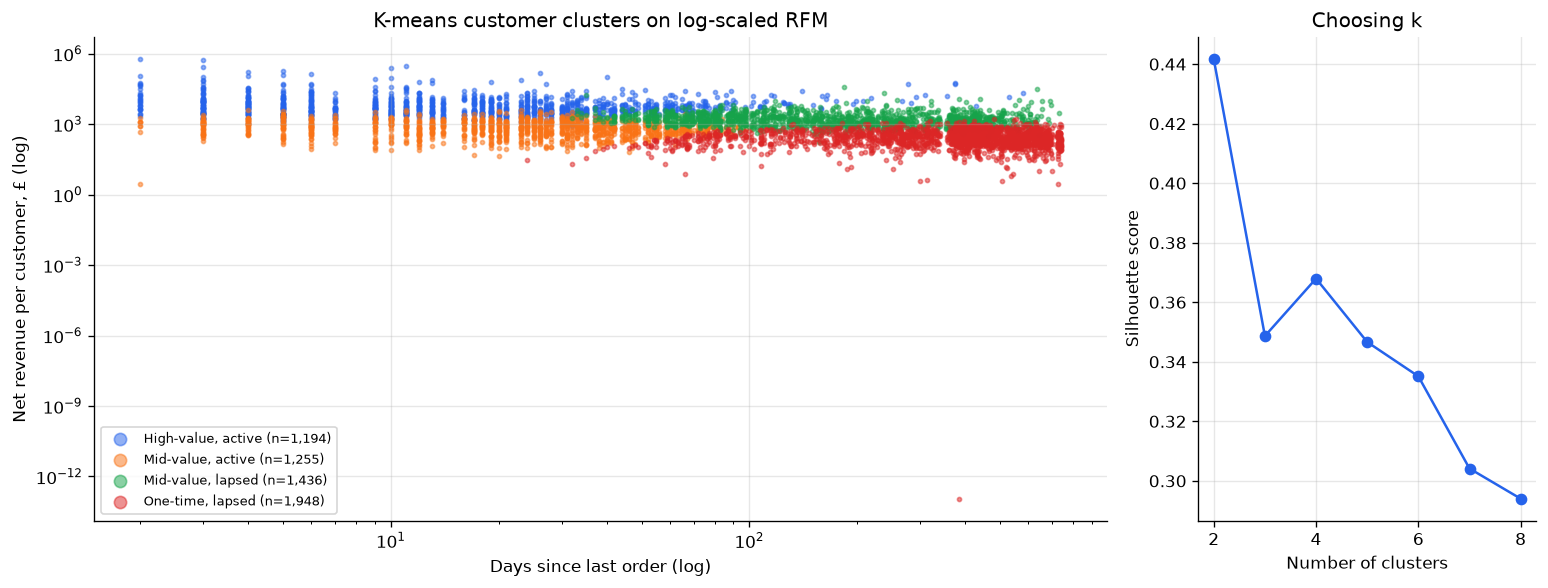

,cluster,name,customers,median_recency_days,median_frequency,median_monetary,revenue,revenue_share
0,2,"High-value, active",1194,17.00,13.00,"4,797.76","12,063,189.89",0.74
1,3,"Mid-value, lapsed",1436,185.00,4.00,"1,426.78","2,662,368.27",0.16
2,0,"Mid-value, active",1255,24.00,3.00,705.79,"1,028,451.42",0.06
3,1,"One-time, lapsed",1948,402.00,1.00,266.40,"607,560.55",0.04


In [8]:
display(Image(FIG + 'kmeans_clusters.png'))
pd.read_csv('../reports/results/kmeans_profile.csv')

* The silhouette score is highest for 2 clusters (active vs. lapsed), which is too coarse to act on; among 3+ clusters **k = 4** is best.
* The four clusters line up well with the RFM grid: ~80% of Champions fall in the *High-value, active* cluster and 99% of Hibernating customers in *One-time, lapsed*. The rule-based segments are therefore a reasonable, explainable approximation of the natural structure in the data.

In [9]:
pd.read_csv('../reports/results/rfm_vs_kmeans.csv', index_col=0).round(2)

,"High-value, active","Mid-value, active","Mid-value, lapsed","One-time, lapsed"
segment,,,,
About to Sleep,0.00,0.20,0.04,0.75
At Risk,0.00,0.00,0.85,0.15
Cannot Lose Them,0.20,0.00,0.80,0.00
Champions,0.80,0.20,0.00,0.00
Hibernating,0.00,0.00,0.01,0.99
Loyal Customers,0.44,0.11,0.45,0.00
Need Attention,0.00,0.22,0.69,0.09
New Customers,0.00,1.00,0.00,0.00
Potential Loyalists,0.00,0.99,0.01,0.00


### Value of a new customer over time

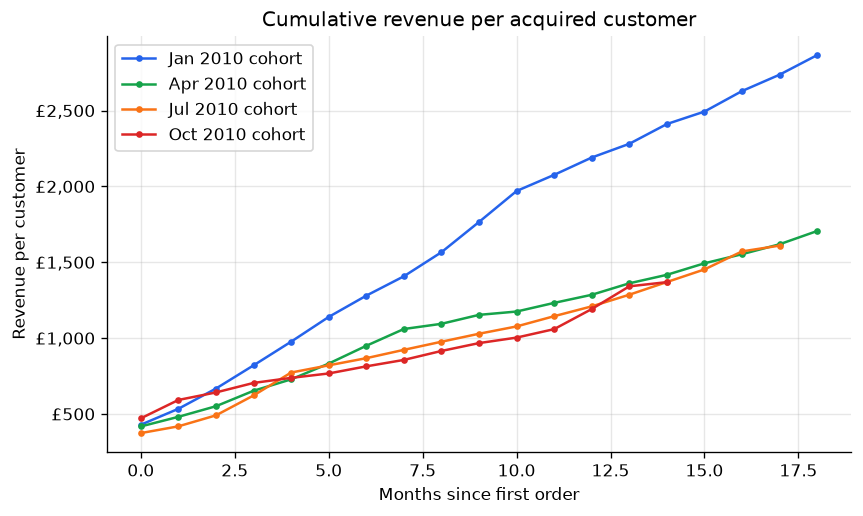

,months_since_first,avg_revenue_per_customer
0,0,477.00
1,3,766.00
2,6,995.00
3,12,"1,463.00"


In [10]:
display(Image(FIG + 'customer_value.png'))
sql('''select months_since_first, round(avg(cumulative_revenue_per_customer)) as
       avg_revenue_per_customer from cohort_cumulative_value
       where months_since_first in (0, 3, 6, 12) and cohort_month >= '2010-01-01'
       group by 1 order by 1''')

A customer's first order is worth a few hundred pounds on average, and cumulative revenue keeps climbing for the following year: the first order is a small part of a customer's value, so **acquisition spend should be judged on 12-month value**, not on first-order margin.

## 4. Products

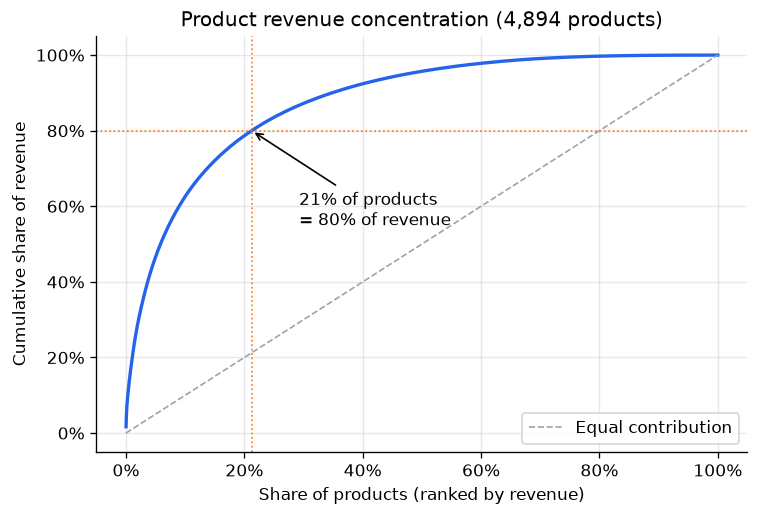

,description,revenue,units,orders
0,REGENCY CAKESTAND 3 TIER,"330,590.00","26,478.00",3918
1,CREAM HANGING HEART T-LIGHT HOLDER,"257,725.00","94,203.00",5365
2,JUMBO BAG RED RETROSPOT,"180,569.00","96,757.00",3989
3,"PAPER CRAFT , LITTLE BIRDIE","168,470.00","80,995.00",1
4,PARTY BUNTING,"148,318.00","28,200.00",2674
5,ASSORTED COLOUR BIRD ORNAMENT,"129,324.00","80,082.00",2807
6,PAPER CHAIN KIT 50'S CHRISTMAS,"117,760.00","35,084.00",2018
7,MEDIUM CERAMIC TOP STORAGE JAR,"81,701.00","78,033.00",247
8,CHILLI LIGHTS,"80,541.00","15,841.00",1135
9,POPCORN HOLDER,"79,520.00","88,499.00",2322


In [11]:
display(Image(FIG + 'product_pareto.png'))
sql('''select description, round(revenue) as revenue, units, orders
       from product_revenue limit 10''')

About **21% of products generate 80% of revenue**, a classic Pareto distribution. The long tail of ~3,800 products could be reviewed for range rationalisation.

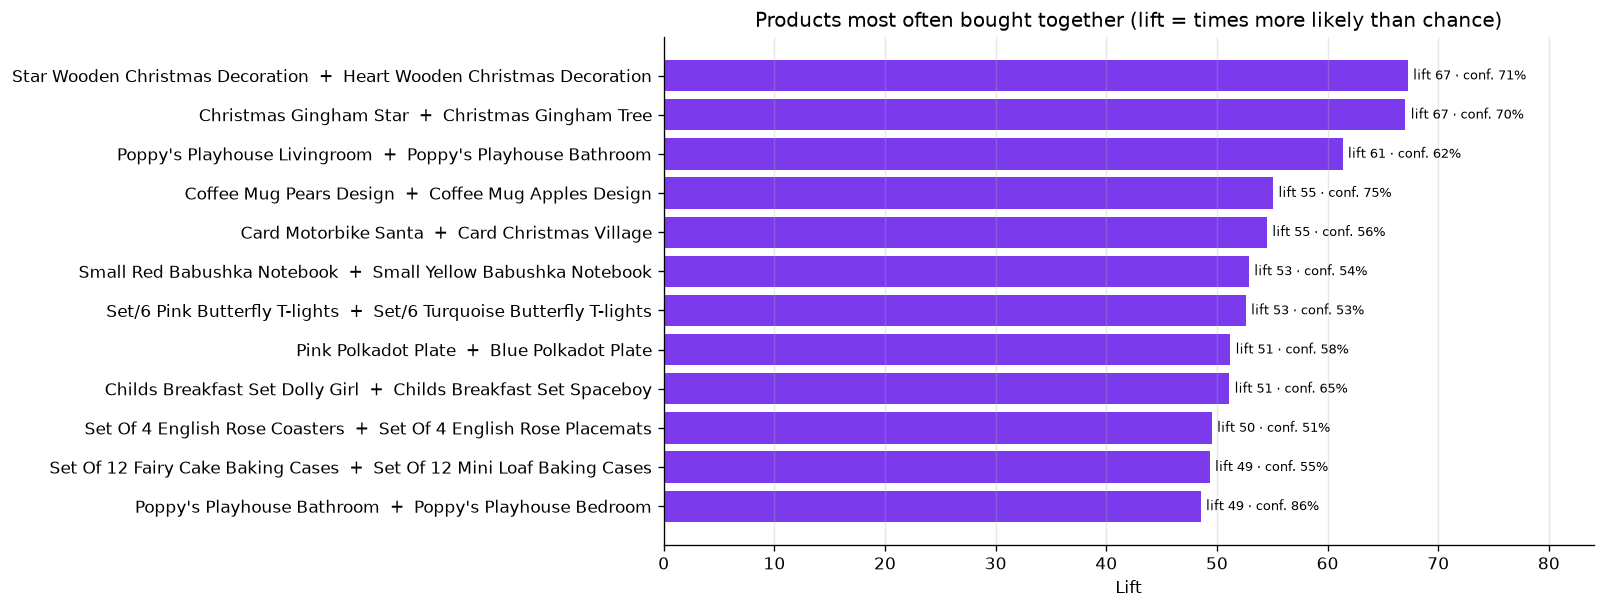

,description_a,description_b,orders_together,confidence,lift
0,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,1426,0.64,6.30
1,JUMBO BAG RED RETROSPOT,JUMBO BAG PINK POLKADOT,1426,0.36,6.30
2,JUMBO BAG RED RETROSPOT,JUMBO STORAGE BAG SUKI,1324,0.33,5.60
3,JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,1324,0.57,5.60
4,RED HANGING HEART T-LIGHT HOLDER,CREAM HANGING HEART T-LIGHT HOLDER,1234,0.70,5.20
5,CREAM HANGING HEART T-LIGHT HOLDER,RED HANGING HEART T-LIGHT HOLDER,1234,0.23,5.20
6,LUNCH BAG RED RETROSPOT,LUNCH BAG BLACK SKULL.,1202,0.39,6.60
7,LUNCH BAG BLACK SKULL.,LUNCH BAG RED RETROSPOT,1202,0.51,6.60
8,60 TEATIME FAIRY CAKE CASES,PACK OF 72 RETROSPOT CAKE CASES,1197,0.56,7.10
9,PACK OF 72 RETROSPOT CAKE CASES,60 TEATIME FAIRY CAKE CASES,1197,0.38,7.10


In [12]:
display(Image(FIG + 'market_basket.png'))
sql('''select description_a, description_b, orders_together,
              round(confidence, 2) as confidence, round(lift, 1) as lift
       from basket_rules order by orders_together desc limit 10''')

* The strongest associations are **variants of the same product family** (heart and star decorations, matching mugs, Poppy's Playhouse rooms): customers buy sets. Product pages should cross-link variants, and bundles could lift order value.
* Some pairs are bought together in hundreds of orders with confidence above 70%, which makes them reliable "frequently bought together" recommendations.

## 5. International markets

In [13]:
sql('select * from country_summary limit 10')

,country,customers,orders,revenue,avg_order_value,orders_per_customer,revenue_share
0,United Kingdom,5334,33361,"14,288,758.75",428.31,6.25,0.84
1,EIRE,3,528,"586,626.08","1,111.03",176.00,0.03
2,Netherlands,22,216,"549,773.41","2,545.25",9.82,0.03
3,Germany,107,753,"383,289.00",509.02,7.04,0.02
4,France,93,590,"309,403.16",524.41,6.34,0.02
5,Australia,15,89,"167,800.01","1,885.39",5.93,0.01
6,Spain,38,144,"97,766.75",678.94,3.79,0.01
7,Switzerland,22,82,"93,400.94","1,139.04",3.73,0.01
8,Sweden,19,98,"86,045.14",878.01,5.16,0.01
9,Denmark,12,42,"67,422.69","1,605.30",3.50,0.00


The UK is 84% of revenue. Several export markets (Netherlands, EIRE, Australia) have few customers but very large orders: these are wholesale accounts, where account management matters more than marketing.

## Recommendations

| Priority | Action | Evidence |
|---|---|---|
| 1 | Win-back campaign for *At Risk* and *Cannot Lose Them* customers | 813 customers, £1.5M historical revenue, inactive ~1 year |
| 2 | Key-account programme for the top 1% of customers | 31% of revenue |
| 3 | Fix acquisition: new customers per month halved in 2011 (280 → 137) | Monthly KPIs |
| 4 | Bundles and "frequently bought together" for product families | Market basket lift 50–67 |
| 5 | Start Q4 campaigns in September, when the seasonal ramp begins | Monthly revenue |

**Limitations:** two years of data; the first cohort is left-censored; ~22% of lines have no customer ID; revenue is in GBP before VAT and costs are unknown, so all value figures are revenue, not profit.